# 01 — Explore fan and valve

Looking and listening only. Code that runs lives in `src/`.

Checklist (Milestone 1):
1. List files, read how names encode domain / label / attributes
2. Read the WAV header (sample rate, channels, length) → update `configs/baseline.yaml`
3. Listen to 3 normal + 3 anomalous test clips
4. Plot their spectrograms side by side
5. Mean log-mel spectrum: normal vs anomalous (fan)
6. One sentence: what does an anomaly sound like?

In [1]:
from pathlib import Path
from collections import Counter

DATA = Path('../data/dev_data/raw')
fan = DATA / 'fan'

# Check the path is right (relative to notebooks/, where this notebook runs)
print('fan folder exists:', fan.exists())
print('contents:', [p.name for p in fan.iterdir()])

train_files = sorted((fan / 'train').glob('*.wav'))
test_files = sorted((fan / 'test').glob('*.wav'))
print(f'\ntrain: {len(train_files)} files, test: {len(test_files)} files')

print('\nFirst 3 train files:')
for f in train_files[:3]:
    print(' ', f.name)

print('\nFirst 3 test files:')
for f in test_files[:3]:
    print(' ', f.name)

# Count files per (split, domain, label) using the file name parts
# e.g. section_00_source_test_anomaly_0000_n_B.wav -> parts[2]=source, parts[3]=test, parts[4]=anomaly
counts = Counter()
for f in train_files + test_files:
    parts = f.stem.split('_')
    counts[(parts[3], parts[2], parts[4])] += 1

print('\n(split, domain, label) -> count')
for key, n in sorted(counts.items()):
    print(f'  {key}: {n}')

fan folder exists: True
contents: ['attributes_00.csv', 'supplemental', 'test', 'train']

train: 1000 files, test: 200 files

First 3 train files:
  section_00_source_train_normal_0000_n_B.wav
  section_00_source_train_normal_0001_n_B.wav
  section_00_source_train_normal_0002_n_B.wav

First 3 test files:
  section_00_source_test_anomaly_0000_n_B.wav
  section_00_source_test_anomaly_0001_n_B.wav
  section_00_source_test_anomaly_0002_n_B.wav

(split, domain, label) -> count
  ('test', 'source', 'anomaly'): 50
  ('test', 'source', 'normal'): 50
  ('test', 'target', 'anomaly'): 50
  ('test', 'target', 'normal'): 50
  ('train', 'source', 'normal'): 990
  ('train', 'target', 'normal'): 10


In [2]:
# TODO: soundfile.info(path) on one file — write the values down
import soundfile as sf

info = sf.info(train_files[0])
print(info)

..\data\dev_data\raw\fan\train\section_00_source_train_normal_0000_n_B.wav
samplerate: 16000 Hz
channels: 1
duration: 10.000 s
format: WAV (Microsoft) [WAV]
subtype: Signed 16 bit PCM [PCM_16]


In [3]:
from collections import Counter

all_files = train_files + test_files
headers = Counter()
for f in all_files:
    i = sf.info(f)
    headers[(i.samplerate, i.channels, round(i.duration, 3), i.subtype)] += 1
print(headers)

Counter({(16000, 1, 10.0, 'PCM_16'): 1200})


In [4]:
valve = DATA / 'valve'
valve_files = sorted((valve / 'train').glob('*.wav')) + sorted((valve / 'test').glob('*.wav'))
print(Counter((i.samplerate, i.channels, round(i.duration, 3), i.subtype)
              for i in map(sf.info, valve_files)))

Counter({(16000, 1, 10.0, 'PCM_16'): 1200})


In [ ]:
# TODO: IPython.display.Audio for 3 normal and 3 anomalous clips
from IPython.display import Audio, display

src_test = [f for f in test_files if '_source_' in f.name]
normal  = [f for f in src_test if '_normal_' in f.name][:3]
anomaly = [f for f in src_test if '_anomaly_' in f.name][:3]

for f in normal + anomaly:
    print(f.name)
    display(Audio(str(f)))

C:\Users\shaki\Downloads\pytorch_ad\.venv\Lib\site-packages\torchaudio\_backend\utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(


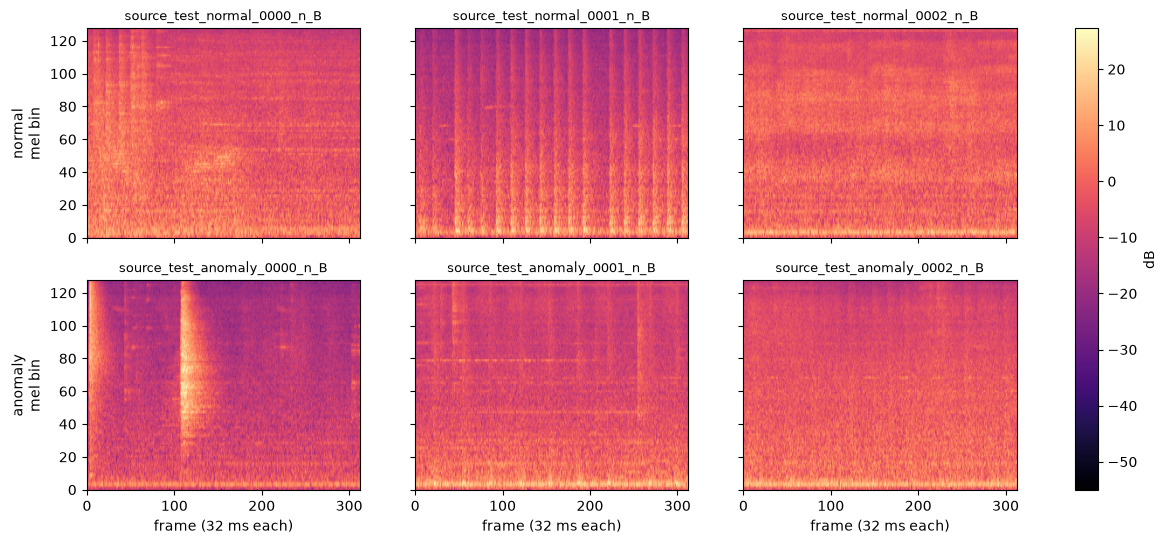

In [6]:
# TODO: spectrogram plots side by side (matplotlib)
import torch, torchaudio
import matplotlib.pyplot as plt

mel_tf = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000, n_fft=1024, hop_length=512, n_mels=128, power=2.0)

def to_db(path):
    wav, sr = torchaudio.load(str(path))
    return 10 * torch.log10(mel_tf(wav[0]) + 1e-10)   # (128, 313)

specs = [to_db(f) for f in normal + anomaly]
vmin = min(s.min() for s in specs).item()
vmax = max(s.max() for s in specs).item()

fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey=True)
for ax, spec, f in zip(axes.flat, specs, normal + anomaly):
    im = ax.imshow(spec, origin='lower', aspect='auto', vmin=vmin, vmax=vmax, cmap='magma')
    ax.set_title(f.stem.replace('section_00_', ''), fontsize=9)
axes[0, 0].set_ylabel('normal\nmel bin')
axes[1, 0].set_ylabel('anomaly\nmel bin')
for ax in axes[1]:
    ax.set_xlabel('frame (32 ms each)')
fig.colorbar(im, ax=axes, label='dB')
plt.show()

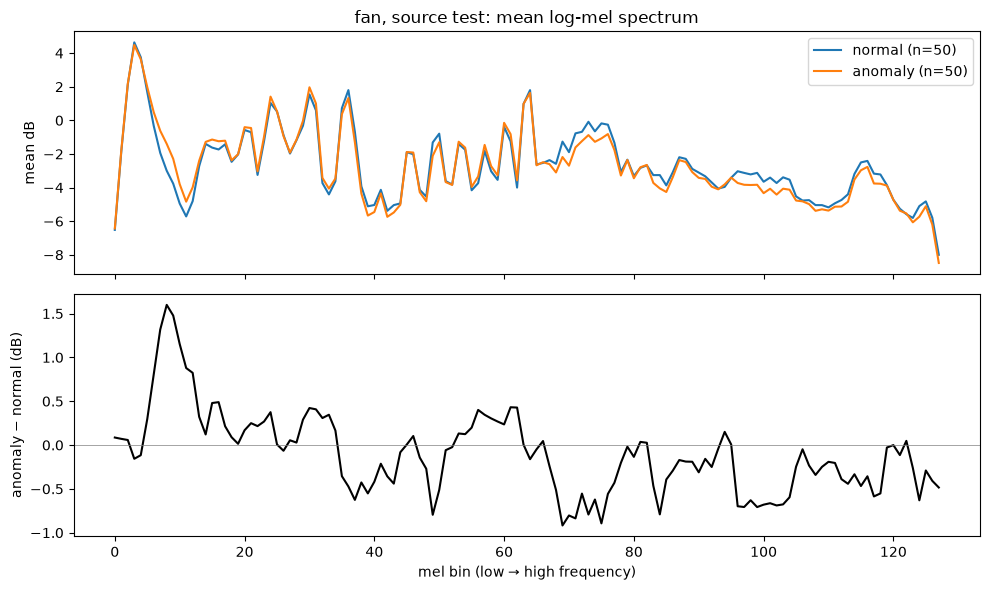

In [7]:
# TODO: mean log-mel spectrum, normal vs anomalous; save to ../results/
import numpy as np

def mean_spectrum(files):
    # average each clip over time -> (128,), then average over clips
    return torch.stack([to_db(f).mean(dim=1) for f in files]).mean(dim=0)

src_normal  = [f for f in src_test if '_normal_' in f.name]
src_anomaly = [f for f in src_test if '_anomaly_' in f.name]

m_norm = mean_spectrum(src_normal)
m_anom = mean_spectrum(src_anomaly)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(m_norm, label=f'normal (n={len(src_normal)})')
ax1.plot(m_anom, label=f'anomaly (n={len(src_anomaly)})')
ax1.set_ylabel('mean dB'); ax1.legend(); ax1.set_title('fan, source test: mean log-mel spectrum')
ax2.plot(m_anom - m_norm, color='k')
ax2.axhline(0, color='gray', lw=0.5)
ax2.set_xlabel('mel bin (low → high frequency)'); ax2.set_ylabel('anomaly − normal (dB)')
plt.tight_layout()
plt.savefig('../results/fan_mean_spectrum.png', dpi=150)
plt.show()

**What differs between normal and anomalous clips:** _TODO — one sentence._

In [ ]:
On average, anomalous fan clips (source domain) have ~1–1.6 dB more energy around 70–240 Hz and ~0.5–0.9 dB less around 2 kHz and 4 kHz than normal 
clips. The differences are small compared with the overall spectrum, so anomalies are subtle in this machine type.